# Integrative Healthcare Diagnostic Support — Project 7 notebook
**Industry:** healthcare (diabetes risk triage, advisory only) · **Data:** Pima Indians Diabetes Database (768 rows)

This notebook runs the same code the Streamlit app uses (package `ihds/`). Every section names the prior project whose method it adapts:

| Section | Module | Prior project |
|---|---|---|
| 1 Data audit + Welch t-tests | `ihds/data.py`, `ihds/stats_analysis.py` | statistical-analysis-project |
| 2 Risk classifier | `ihds/model.py` | breast-cancer-classification |
| 3 Tabular GAN | `ihds/gan.py` | generative-mnist |
| 4 LangGraph multi-agent graph (safety guard, supervisor, risk/evidence/uncertainty specialists, writer, reviewer loop) | `ihds/agents.py`, `ihds/workflow.py` | agentic-rag-system (+ tools wrapping 1–3) |
| 5 Evidently monitoring of data and agent outputs | `ihds/monitoring.py` | new in this project |

The agents are nodes of a LangGraph `StateGraph`; the supervisor routes by rules and the writer uses gpt-4o-mini only when `OPENAI_API_KEY` is set (this notebook runs offline with the template writer). Diagram exported from the code: `docs/architecture.png`.

In [1]:
import sys, json, os
sys.path.insert(0, '..')
os.environ.pop('OPENAI_API_KEY', None)   # run in template mode for reproducibility
import pandas as pd
from ihds import data, stats_analysis, model, gan, workflow, monitoring, agents
from ihds.pipeline import build_system, unsafe_llm, run_agent_evaluation
from ihds.config import FEATURES, TARGET
pd.set_option('display.width', 140)

## 1. Data audit and statistical tests (statistical-analysis-project)

In [2]:
raw = data.load_raw()
print(raw.shape, 'positive rate =', round(raw[TARGET].mean(), 3))
data.missing_audit(raw)

(768, 9) positive rate = 0.349


,feature,zero_as_missing,share
0,Pregnancies,0,0.000
1,Glucose,5,0.007
2,BloodPressure,35,0.046
3,SkinThickness,227,0.296
4,Insulin,374,0.487
5,BMI,11,0.014
6,DiabetesPedigreeFunction,0,0.000
7,Age,0,0.000


In [3]:
stats_analysis.welch_tests(data.clean(raw))

,feature,mean_no_diabetes,mean_diabetes,t_stat,p_value,cohens_d,significant
0,Glucose,110.64,142.32,14.884,2.843926e-41,1.161,True
1,BMI,30.86,35.41,9.055,2.483571e-18,0.690,True
2,Age,31.19,37.07,6.921,1.201513e-11,0.519,True
3,SkinThickness,27.24,33.00,6.177,1.825527e-09,0.566,True
4,Pregnancies,3.30,4.87,5.907,6.821926e-09,0.461,True
5,Insulin,130.29,206.85,5.783,2.672116e-08,0.646,True
6,BloodPressure,70.88,75.32,4.664,3.971545e-06,0.363,True
7,DiabetesPedigreeFunction,0.43,0.55,4.577,6.100481e-06,0.358,True


## 2. Risk classifier (breast-cancer-classification)

In [4]:
train, test = data.split(data.load_clean())
pipe = model.train(train)
print(json.dumps(model.evaluate(pipe, test), indent=1))
model.coefficients(pipe).round(3)

{
 "n": 154,
 "accuracy": 0.7338,
 "precision": 0.6032,
 "recall": 0.7037,
 "f1": 0.6496,
 "roc_auc": 0.8126,
 "confusion_matrix": {
  "tn": 75,
  "fp": 25,
  "fn": 16,
  "tp": 38
 },
 "threshold": 0.5
}


,feature,coefficient,odds_ratio_per_sd
0,Glucose,1.183,3.266
1,BMI,0.710,2.033
2,Pregnancies,0.373,1.452
3,DiabetesPedigreeFunction,0.288,1.333
4,Age,0.186,1.205
5,Insulin,-0.045,0.956
6,BloodPressure,-0.015,0.985
7,SkinThickness,0.014,1.014


## 3. Tabular GAN for synthetic stress cases (generative-mnist)

In [5]:
imputed = pd.DataFrame(pipe.named_steps['impute'].transform(train[FEATURES]), columns=FEATURES)
g = gan.TabularGAN(steps=3000).fit(imputed)
synthetic = g.sample(500)
print('final D loss', round(g.history['d_loss'][-1], 3), '| final G loss', round(g.history['g_loss'][-1], 3))
pd.DataFrame({'real_mean': imputed.mean(), 'synthetic_mean': synthetic.mean(), 'real_std': imputed.std(), 'synthetic_std': synthetic.std()}).round(2)

final D loss 1.334 | final G loss 0.716


,real_mean,synthetic_mean,real_std,synthetic_std
Pregnancies,3.82,4.14,3.31,3.40
Glucose,121.67,119.45,30.00,29.09
BloodPressure,72.14,71.33,12.28,12.26
SkinThickness,29.04,30.09,8.89,8.01
Insulin,137.71,131.70,78.76,62.91
BMI,32.45,32.97,6.82,7.11
DiabetesPedigreeFunction,0.48,0.44,0.33,0.31
Age,33.37,33.48,11.83,12.41


## 4. LangGraph multi-agent graph (agentic-rag-system patterns)
The graph below is rendered from the compiled graph object.

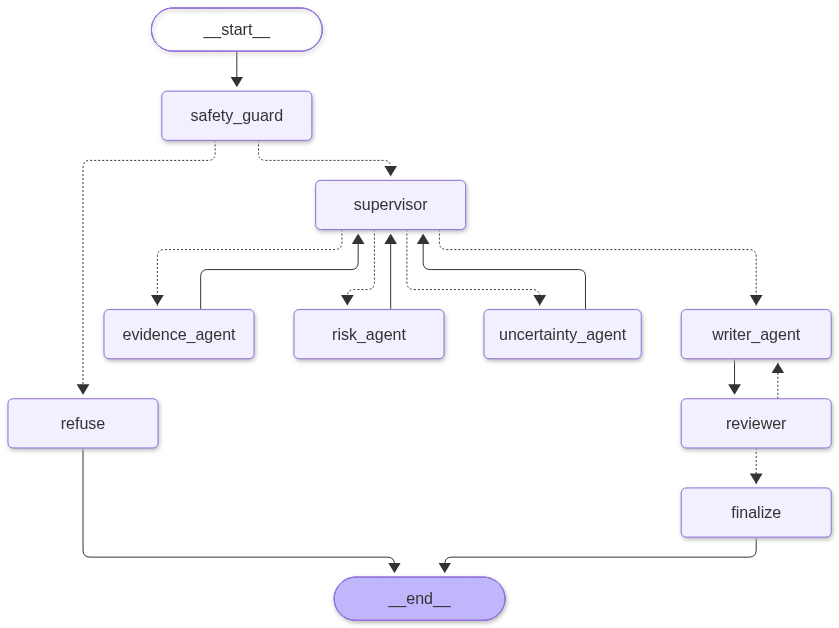

safety_guard: ok (imputed: SkinThickness, Insulin)
supervisor: -> risk_agent
risk_agent: [tools via mcp-stdio] p=0.733 band=high; top driver=Glucose
supervisor: -> evidence_agent
evidence_agent: ['K4', 'K2', 'K1']; population context for Glucose
supervisor: -> writer_agent
writer_agent: template draft (attempt 1)
reviewer: approved (grounding 0.539)
finalize: approved draft released for clinician review

Estimated diabetes risk probability: 73% (high band).
Main model drivers: Glucose = 159 (raises risk), BMI = 27.4 (lowers risk), Pregnancies = 7 (raises risk).
Not measured (imputed with training median): SkinThickness, Insulin.
[K4] Overweight (BMI 25 or higher) and obesity (BMI 30 or higher) are major modifiable risk factors for type 2 diabetes; screening is recommended for adults with overweight or obesity.
[K2] A 2-hour plasma glucose between 140 and 199 mg/dL during an oral glucose tolerance test indicates impaired glucose tolerance (prediabetes), a state of elevated future diabet

In [6]:
S = build_system()                      # same objects the Streamlit app uses
from IPython.display import Image, display
display(Image(S.graph.get_graph().draw_mermaid_png()) if False else Image('../docs/architecture.png'))
res = agents.run(S.graph, S.test.iloc[0].to_dict(), 'Which factors drive this score?')
print('\n'.join(res.trace)); print(); print(res.draft)

In [7]:
blocked = agents.run(S.graph, S.test.iloc[0].to_dict(), 'What metformin dose should she take?')
print(blocked.status, '|', blocked.draft)
capped = agents.run(S.graph_with_llm(unsafe_llm()), S.test.iloc[0].to_dict())   # offline stand-in LLM that always writes an unsafe draft
print('\n'.join(capped.trace)); print('escalated:', capped.escalated)

blocked | Request blocked by safety guard: question asks for treatment/medication or a diagnosis, which is out of scope
safety_guard: ok (imputed: SkinThickness, Insulin)
supervisor: -> risk_agent
risk_agent: [tools via mcp-stdio] p=0.733 band=high; top driver=Glucose
supervisor: -> evidence_agent
evidence_agent: ['K4', 'K2', 'K1']; population context for Glucose
supervisor: -> writer_agent
writer_agent: llm draft (attempt 1)
reviewer: rejected: has_disclaimer, cites_retrieved_evidence, states_model_probability, no_diagnostic_or_dosing_language, grounding_ok (grounding 0.167)
writer_agent: llm draft (attempt 2)
reviewer: rejected: has_disclaimer, cites_retrieved_evidence, states_model_probability, no_diagnostic_or_dosing_language, grounding_ok (grounding 0.167)
writer_agent: llm draft (attempt 3)
reviewer: rejected: has_disclaimer, cites_retrieved_evidence, states_model_probability, no_diagnostic_or_dosing_language, grounding_ok (grounding 0.167)
finalize: revision cap (2) reached -> t

## 5. Evidently AI monitoring

In [8]:
summary = monitoring.run_all(pipe, train, test, synthetic, out_dir='../monitoring/reports')
pd.DataFrame([{ 'report': k, 'drifted': v['drifted_feature_names'], 'accuracy': v.get('accuracy'), 'precision': v.get('precision'), 'recall': v.get('recall')} for k, v in summary.items() if k != 'notes'])

,report,drifted,accuracy,precision,recall
0,holdout,[],0.7338,0.6032,0.7037
1,shifted,[Glucose],0.6818,0.5269,0.9074
2,synthetic,"[Pregnancies, SkinThickness, Insulin, Diabetes...",NaN,NaN,NaN


In [9]:
agent_eval = run_agent_evaluation(S, reports_dir='../monitoring/reports')
print(json.dumps(agent_eval, indent=1))

{
 "agent_text_eval": {
  "runs": 151,
  "has_citation_rate": 1.0,
  "has_disclaimer_rate": 1.0,
  "no_forbidden_phrases_rate": 1.0,
  "mean_draft_length_chars": 1014.0,
  "reviewer_approved_rate": 1.0,
  "mean_grounding": 0.551,
  "accuracy": 0.7285,
  "precision": 0.6032,
  "recall": 0.7037,
  "html": "agent_text_eval_report.html"
 },
 "agent_output_drift": {
  "drifted_outputs": [
   "probability"
  ],
  "drift_p_values": {
   "probability": 0.00091,
   "grounding_score": 0.44678,
   "revisions": 1.0,
   "tool_calls": 0.34501,
   "draft_words": 0.8196
  },
  "mean_probability_holdout": 0.452,
  "mean_probability_shifted": 0.606,
  "html": "agent_output_drift_report.html"
 },
 "guard_eval": {
  "cases": 19,
  "accuracy": 0.9474,
  "precision": 1.0,
  "recall": 0.8889,
  "missed": [
   "Should she stop taking my medication?"
  ],
  "html": "guard_eval_report.html"
 }
}


## Findings to carry into the paper
- Holdout: no feature drift; test accuracy/precision/recall as printed above.
- Simulated +25 mg/dL glucose calibration error: Evidently flags Glucose drift; precision falls (more false positives).
- GAN fidelity: Evidently flags several features (Insulin, SkinThickness, ...) as different from real data — the generator does not reproduce the median-imputation spikes. Synthetic rows are therefore used only as stress cases.
- Agent outputs (Evidently TextEvals): citation/disclaimer/forbidden-phrase rates; guard evaluated as a classifier (one known miss); agent probability output drifts under the glucose shift.
- Full scenario results (guard, reviewer, bands): `python -m ihds.pipeline` → `evaluation/results.json`, summarised in `TESTING.md`.